# Day 14: A/B Testing and Business Statistics

## Learning Objectives

By the end of this notebook, I will be able to:

1. Understand important business statistics concepts.
2. Identify and calculate business KPIs.
3. Understand A/B testing and its purpose.
4. Differentiate between control and treatment groups.
5. Calculate conversion rates.
6. Perform a two-proportion Z-test.
7. Compare revenue per user using Welch's T-test.
8. Interpret p-values and confidence intervals.
9. Understand statistical and practical significance.
10. Make data-driven business recommendations.

**Business Scenario:**

An e-commerce company wants to test whether a new
website design improves its purchase conversion rate.

We will compare the existing design (Control Group)
with the new design (Treatment Group).

In [1]:
# Import required libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
from statsmodels.stats.proportion import proportions_ztest

# Set random seed for reproducibility
np.random.seed(42)

# Display settings
pd.set_option("display.max_columns", None)

## 1. Understanding Business Statistics

Business Statistics refers to the use of statistical methods
to analyze business data and support decision-making.

It helps organizations understand performance,
identify trends, compare alternatives, and reduce uncertainty.

### Common Business Applications

- Sales and Revenue Analysis
- Marketing Campaign Analysis
- Customer Behavior Analysis
- Customer Retention Analysis
- Product Performance
- Operational Performance
- Financial Analysis
- Business Forecasting

### Descriptive vs Inferential Statistics

**Descriptive Statistics:**
Summarizes and describes the available data.

Examples:
- Average order value
- Total revenue
- Conversion rate

**Inferential Statistics:**
Uses sample data to draw conclusions about a larger population.

Examples:
- A/B testing
- Hypothesis testing
- Estimating conversion rate differences

## 2. Important Business KPIs

A Key Performance Indicator (KPI) is a measurable value
used to evaluate business performance.

### Common Business Metrics

**1. Revenue**

Total money generated from sales.

Revenue = Price × Quantity Sold

**2. Average Order Value (AOV)**

Average revenue generated per order.

AOV = Total Revenue / Total Orders

**3. Conversion Rate**

Percentage of visitors who complete a desired action.

Conversion Rate = (Conversions / Visitors) × 100

**4. Customer Acquisition Cost (CAC)**

Average cost of acquiring one new customer.

CAC = Acquisition Cost / New Customers Acquired

**5. Customer Retention Rate**

Percentage of customers retained during a period.

Retention Rate =
((Customers at End - New Customers Acquired)
 / Customers at Start) × 100

**6. Profit Margin**

Percentage of revenue remaining as profit.

Profit Margin = (Profit / Revenue) × 100

**Important:**

Always define the business metric carefully.
The denominator, time period, and customer population
must be consistent when comparing KPIs.

In [2]:
# Create sample business performance data

business_data = {
    "Month": ["January", "February", "March", "April"],
    "Revenue": [120000, 135000, 150000, 165000],
    "Orders": [1000, 1080, 1200, 1250],
    "Marketing_Cost": [20000, 22000, 25000, 27000],
    "New_Customers": [200, 220, 250, 270]
}

business_df = pd.DataFrame(business_data)

display(business_df)

,Month,Revenue,Orders,Marketing_Cost,New_Customers
0,January,120000,1000,20000,200
1,February,135000,1080,22000,220
2,March,150000,1200,25000,250
3,April,165000,1250,27000,270


In [3]:
# Calculate business KPIs

business_df["AOV"] = (
    business_df["Revenue"] / business_df["Orders"]
)

business_df["CAC"] = (
    business_df["Marketing_Cost"] / business_df["New_Customers"]
)

business_df["Profit"] = (
    business_df["Revenue"] - business_df["Marketing_Cost"]
)

business_df["Profit_Margin"] = (
    business_df["Profit"] / business_df["Revenue"] * 100
)

display(business_df.round(2))

,Month,Revenue,Orders,Marketing_Cost,New_Customers,AOV,CAC,Profit,Profit_Margin
0,January,120000,1000,20000,200,120.0,100.0,100000,83.33
1,February,135000,1080,22000,220,125.0,100.0,113000,83.70
2,March,150000,1200,25000,250,125.0,100.0,125000,83.33
3,April,165000,1250,27000,270,132.0,100.0,138000,83.64


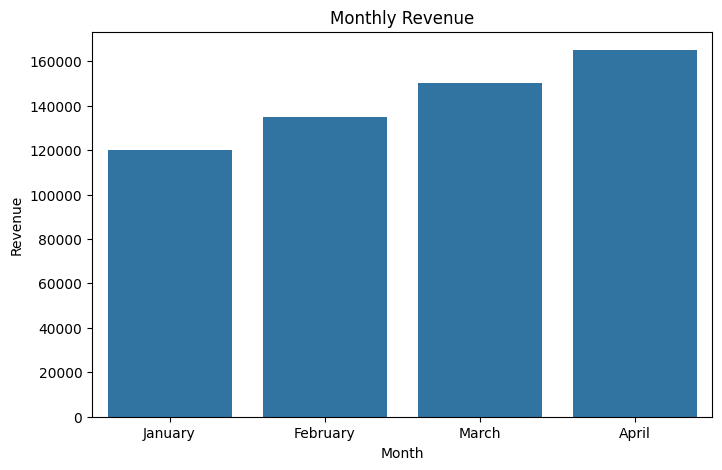

In [4]:
# Visualize monthly revenue

plt.figure(figsize=(8, 5))

sns.barplot(
    data=business_df,
    x="Month",
    y="Revenue"
)

plt.title("Monthly Revenue")
plt.xlabel("Month")
plt.ylabel("Revenue")

plt.show()

## 3. Understanding A/B Testing

A/B Testing is an experimental method used to compare
two versions of a product, website, advertisement,
or business strategy.

It helps determine whether a change improves
a specific business metric.

### Two Groups

**Control Group (A):**
Users experience the existing version.

**Treatment Group (B):**
Users experience the new or modified version.

### Example

An e-commerce company changes its checkout button.

- Version A: Existing checkout button
- Version B: New checkout button

The company wants to determine whether Version B
improves the purchase conversion rate.

### Important Elements of A/B Testing

1. Define a clear business objective.
2. Select a primary success metric.
3. Randomly assign eligible users to groups.
4. Run both versions under comparable conditions.
5. Collect sufficient data.
6. Perform statistical analysis.
7. Evaluate business impact before making a decision.

**Important:**

Randomization helps reduce selection bias.
The experiment should ideally change only the intended factor.

## 4. Hypotheses in A/B Testing

We use hypothesis testing to evaluate whether
the observed difference between two groups
provides sufficient statistical evidence.

### Example: Conversion Rate

Null Hypothesis (H0):

The conversion rates of Group A and Group B are equal.

Alternative Hypothesis (H1):

The conversion rates of Group A and Group B are different.

For a two-sided test:

H0: pA = pB

H1: pA != pB

Where:

- pA = Population conversion rate of Group A
- pB = Population conversion rate of Group B

### Significance Level

We commonly use alpha = 0.05.

If p-value < 0.05:
Reject the null hypothesis.

If p-value >= 0.05:
Do not reject the null hypothesis.

**Remember:**

A statistically significant result does not automatically
mean that the change is valuable for the business.

In [5]:
# Create sample A/B testing data

ab_data = pd.DataFrame({
    "Group": ["A", "B"],
    "Visitors": [10000, 10000],
    "Conversions": [1000, 1150]
})

ab_data["Non_Conversions"] = (
    ab_data["Visitors"] - ab_data["Conversions"]
)

ab_data["Conversion_Rate"] = (
    ab_data["Conversions"] / ab_data["Visitors"] * 100
)

display(ab_data)

,Group,Visitors,Conversions,Non_Conversions,Conversion_Rate
0,A,10000,1000,9000,10.0
1,B,10000,1150,8850,11.5


In [6]:
# Compare conversion rates

conversion_a = (
    ab_data.loc[ab_data["Group"] == "A", "Conversion_Rate"].iloc[0]
)

conversion_b = (
    ab_data.loc[ab_data["Group"] == "B", "Conversion_Rate"].iloc[0]
)

absolute_lift = conversion_b - conversion_a

relative_lift = (
    (conversion_b - conversion_a) / conversion_a
) * 100

print("Group A Conversion Rate:", round(conversion_a, 2), "%")
print("Group B Conversion Rate:", round(conversion_b, 2), "%")

print("Absolute Lift:", round(absolute_lift, 2), "percentage points")
print("Relative Lift:", round(relative_lift, 2), "%")

Group A Conversion Rate: 10.0 %
Group B Conversion Rate: 11.5 %
Absolute Lift: 1.5 percentage points
Relative Lift: 15.0 %


### Understanding Conversion Rate Lift

There are two useful ways to compare conversion rates.

**Absolute Lift:**

Treatment Conversion Rate - Control Conversion Rate

Example:

11.5% - 10% = 1.5 percentage points

**Relative Lift:**

((Treatment Rate - Control Rate) / Control Rate) × 100

Example:

((11.5 - 10) / 10) × 100 = 15%

### Important Difference

- Absolute lift = 1.5 percentage points.
- Relative lift = 15%.

Do not confuse percentage points with percentage change.

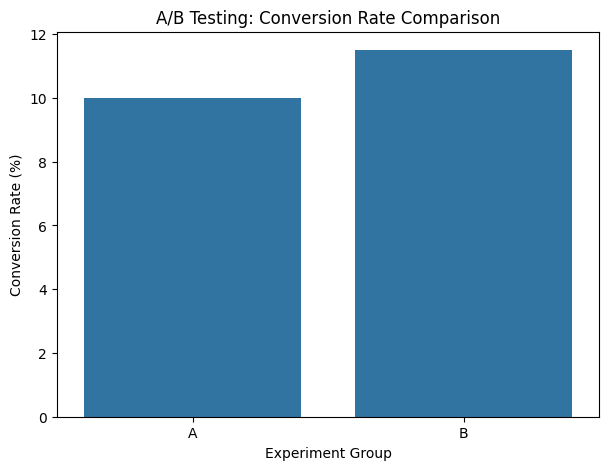

In [7]:
# Visualize conversion rates

plt.figure(figsize=(7, 5))

sns.barplot(
    data=ab_data,
    x="Group",
    y="Conversion_Rate"
)

plt.title("A/B Testing: Conversion Rate Comparison")
plt.xlabel("Experiment Group")
plt.ylabel("Conversion Rate (%)")

plt.show()

## 5. Two-Proportion Z-Test

A two-proportion Z-test helps compare
the proportions of two independent groups.

In A/B testing, it is commonly used
to compare conversion rates.

### Why Use This Test?

Our outcome is categorical:

- Converted
- Not Converted

We want to compare the conversion proportions
of Group A and Group B.

### Hypotheses

H0: pA = pB

H1: pA != pB

### Decision Rule

At alpha = 0.05:

- p-value < 0.05: Reject H0.
- p-value >= 0.05: Do not reject H0.

**Assumptions and Considerations**

- Two independent groups.
- Each observation belongs to one group.
- Each observation has a binary outcome.
- Observations should be independent within groups.
- Sample sizes should be sufficient for the normal approximation.

Random assignment and correct experiment design
are essential for reliable conclusions.

In [8]:
# Perform a two-proportion Z-test

successes = np.array([1000, 1150])

observations = np.array([10000, 10000])

z_stat, p_value = proportions_ztest(
    count=successes,
    nobs=observations,
    alternative="two-sided"
)

print("Z-Statistic:", round(z_stat, 4))
print("P-value:", p_value)

alpha = 0.05

if p_value < alpha:
    print("Decision: Reject the Null Hypothesis")
else:
    print("Decision: Do Not Reject the Null Hypothesis")

Z-Statistic: -3.4243
P-value: 0.0006164549192148455
Decision: Reject the Null Hypothesis


### Interpreting the A/B Test

The p-value helps us evaluate whether
the observed difference is statistically significant
under the null hypothesis.

If p-value < 0.05:

There is statistically significant evidence
that the two population conversion rates differ.

If p-value >= 0.05:

There is insufficient statistical evidence
to conclude that the conversion rates differ.

**Important:**

A p-value is not the probability that the null hypothesis
is true.

It is the probability, assuming the null hypothesis
and test assumptions are correct, of observing a result
at least as extreme as the one obtained.

## 6. Confidence Interval for Conversion Rate Difference

A confidence interval provides a range of plausible values
for the difference between two population proportions.

We will calculate an approximate 95% confidence interval
for:

Treatment Conversion Rate - Control Conversion Rate

If the interval does not contain zero,
the difference is statistically significant
at approximately the 5% level for a two-sided test,
under the same large-sample assumptions.

**Note:**

This is an unpooled normal-approximation interval.
It is not the same as the pooled interval used
in the two-proportion Z-test.

In [9]:
# Calculate an approximate confidence interval
# for the difference in conversion proportions

p_a = successes[0] / observations[0]
p_b = successes[1] / observations[1]

difference = p_b - p_a

se_difference = np.sqrt(
    (p_a * (1 - p_a) / observations[0])
    +
    (p_b * (1 - p_b) / observations[1])
)

z_critical = stats.norm.ppf(0.975)

lower_bound = difference - z_critical * se_difference
upper_bound = difference + z_critical * se_difference

print("Difference (B - A):", round(difference, 4))

print(
    "95% Confidence Interval:",
    (round(lower_bound, 4), round(upper_bound, 4))
)

Difference (B - A): 0.015
95% Confidence Interval: (np.float64(0.0064), np.float64(0.0236))


## 7. Revenue per User Comparison

Conversion rate is not the only important business metric.

A new design may increase conversions
but attract lower-value purchases.

Therefore, we should also evaluate revenue per user.

Revenue per User = Total Revenue / Number of Users

We will compare revenue per user between
the Control and Treatment groups.

Since revenue is numerical, we can use
an independent two-sample t-test.

We will use Welch's T-test because it does not
assume equal population variances.

### Hypotheses

H0: Mean Revenue per User is equal in both groups.

H1: Mean Revenue per User differs between both groups.

In [10]:
# Generate sample revenue per user data

revenue_a = np.random.normal(
    loc=120,
    scale=35,
    size=1000
)

revenue_b = np.random.normal(
    loc=128,
    scale=38,
    size=1000
)

# Revenue cannot be negative
revenue_a = np.maximum(revenue_a, 0)
revenue_b = np.maximum(revenue_b, 0)

revenue_df = pd.DataFrame({
    "Group": ["A"] * len(revenue_a) + ["B"] * len(revenue_b),
    "Revenue_Per_User": np.concatenate([revenue_a, revenue_b])
})

display(revenue_df.head())

,Group,Revenue_Per_User
0,A,137.384995
1,A,115.160749
2,A,142.669099
3,A,173.306045
4,A,111.804632


In [11]:
# Calculate group-level revenue metrics

revenue_summary = (
    revenue_df.groupby("Group")["Revenue_Per_User"]
    .agg(["count", "mean", "median", "std"])
    .round(2)
)

display(revenue_summary)

,count,mean,median,std
Group,,,,
A,1000,120.68,120.89,34.27
B,1000,130.69,130.40,37.90


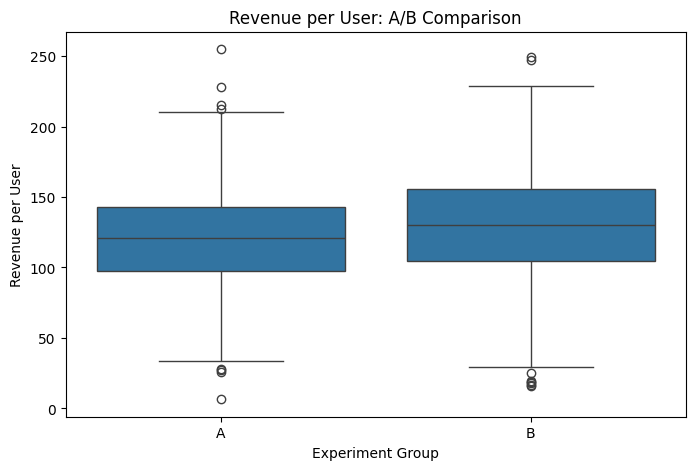

In [12]:
# Visualize revenue per user

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=revenue_df,
    x="Group",
    y="Revenue_Per_User"
)

plt.title("Revenue per User: A/B Comparison")
plt.xlabel("Experiment Group")
plt.ylabel("Revenue per User")

plt.show()

In [13]:
# Perform Welch's independent two-sample T-test

t_stat, revenue_p_value = stats.ttest_ind(
    revenue_a,
    revenue_b,
    equal_var=False,
    alternative="two-sided"
)

print("T-Statistic:", round(t_stat, 4))
print("P-value:", round(revenue_p_value, 4))

if revenue_p_value < 0.05:
    print("Decision: Reject the Null Hypothesis")
else:
    print("Decision: Do Not Reject the Null Hypothesis")

T-Statistic: -6.1977
P-value: 0.0
Decision: Reject the Null Hypothesis


### Revenue Test Interpretation

We compare the average revenue per user
between the Control and Treatment groups.

If p-value < 0.05:

There is statistically significant evidence
of a difference in average revenue per user.

If p-value >= 0.05:

There is insufficient statistical evidence
of a difference in average revenue per user.

**Business Reminder:**

A higher average does not automatically guarantee
a statistically significant or commercially valuable improvement.

We should consider:
- Revenue impact
- Profitability
- Customer experience
- Implementation costs
- Other important business metrics

## 8. Statistical Significance vs Practical Significance

### Statistical Significance

Indicates whether the observed result provides
sufficient statistical evidence against the null hypothesis.

It is commonly evaluated using a p-value
and a predefined significance level.

### Practical Significance

Indicates whether the observed result is large enough
to matter in the real business context.

### Example

A website conversion rate improves from 10%
to 10.1%.

With a very large sample, this small difference
might become statistically significant.

However, the improvement may not justify
the cost of implementing the change.

**Key Lesson:**

A good business decision considers both
statistical evidence and actual business impact.

## 9. Important A/B Testing Considerations

### 1. Randomization

Randomly assign eligible users to groups
to reduce selection bias.

### 2. Sample Size

Use an appropriate sample size based on:
- Baseline conversion rate
- Minimum detectable effect
- Significance level
- Statistical power

### 3. Experiment Duration

Run the experiment long enough to capture
normal business patterns and avoid misleading
results caused by day-of-week effects.

### 4. Sample Ratio Mismatch

Check whether the actual group allocation
matches the planned allocation.

For example, a planned 50:50 split should be
reasonably close to the observed allocation.

Unexpected differences may indicate tracking
or randomization problems.

### 5. Avoid Repeated Peeking

Repeatedly checking results and stopping
as soon as a p-value becomes significant
can increase false-positive risk.

Use a predefined analysis plan.

### 6. Guardrail Metrics

Monitor other important metrics such as:
- Refund rate
- Customer complaints
- Average order value
- Website performance

A successful experiment should not improve
one metric while seriously harming another.

## 10. Business Decision-Making

A/B testing results should be interpreted
along with business objectives.

### Example Decision Framework

| Result | Possible Business Decision |
|---|---|
| Significant improvement and positive business impact | Consider implementing Treatment |
| Significant negative impact | Retain Control or investigate |
| No statistically significant difference | Gather more evidence or retain Control |
| Statistical improvement but negligible business value | Evaluate implementation cost |
| Primary metric improves but guardrail metric worsens | Investigate trade-offs |

**Important:**

Failure to reject the null hypothesis
does not prove that both versions are identical.

A business decision should consider uncertainty,
costs, risks, and long-term impact.

In [14]:
# Prepare an A/B testing business summary

ab_summary = pd.DataFrame({
    "Metric": [
        "Visitors",
        "Conversions",
        "Conversion Rate (%)"
    ],
    "Control_A": [
        ab_data.loc[0, "Visitors"],
        ab_data.loc[0, "Conversions"],
        round(conversion_a, 2)
    ],
    "Treatment_B": [
        ab_data.loc[1, "Visitors"],
        ab_data.loc[1, "Conversions"],
        round(conversion_b, 2)
    ]
})

display(ab_summary)

print("Conversion Rate Absolute Lift:",
      round(absolute_lift, 2), "percentage points")

print("Conversion Rate Relative Lift:",
      round(relative_lift, 2), "%")

print("Conversion Test P-value:", round(p_value, 6))

print("Revenue Test P-value:", round(revenue_p_value, 6))

,Metric,Control_A,Treatment_B
0,Visitors,10000.0,10000.0
1,Conversions,1000.0,1150.0
2,Conversion Rate (%),10.0,11.5


Conversion Rate Absolute Lift: 1.5 percentage points
Conversion Rate Relative Lift: 15.0 %
Conversion Test P-value: 0.000616
Revenue Test P-value: 0.0


## 11. Business Applications

### Data Analyst

- Calculate and monitor business KPIs.
- Compare business performance across groups.
- Analyze conversion and retention metrics.
- Prepare experiment result reports.

### Marketing Analyst

- Compare advertising campaigns.
- Evaluate landing page performance.
- Analyze conversion rate improvements.
- Measure campaign effectiveness.

### Business Analyst

- Support business decisions using statistical evidence.
- Evaluate product and process changes.
- Identify business performance trends.
- Communicate experiment results to stakeholders.

### Data Scientist

- Design and analyze experiments.
- Estimate treatment effects.
- Calculate sample sizes and statistical power.
- Apply advanced experimentation methods.

## 12. Quick Revision

| Concept | Meaning |
|---|---|
| Business Statistics | Statistics applied to business decisions |
| KPI | Key Performance Indicator |
| A/B Testing | Comparing two versions using an experiment |
| Control Group | Group receiving the existing version |
| Treatment Group | Group receiving the new version |
| Conversion Rate | Conversions divided by eligible visitors |
| Absolute Lift | Difference between two rates |
| Relative Lift | Percentage change compared with the control |
| Two-Proportion Z-Test | Compares two independent proportions |
| Welch's T-Test | Compares two independent means without assuming equal variances |
| P-value | Evidence against the null hypothesis |
| Confidence Interval | Range of plausible parameter values |
| Guardrail Metric | Metric monitored to detect unintended harm |
| Practical Significance | Whether the effect matters commercially |

### Important Reminders

1. Define the primary metric before starting an experiment.
2. Randomization helps reduce selection bias.
3. Compare equivalent and independent groups.
4. Statistical significance is not the same as business value.
5. Avoid repeatedly checking results without a suitable testing plan.
6. Monitor guardrail metrics.
7. Do not interpret a non-significant result as proof of no effect.

## 13. Interview Questions and Answers

### Q1. What is A/B Testing?

A/B testing is an experimental method
used to compare two versions of a product,
website, advertisement, or business strategy.

### Q2. What is the difference between Control and Treatment groups?

The Control group receives the existing version,
while the Treatment group receives the new version.

### Q3. Why is randomization important?

It helps distribute user characteristics
across groups and reduces selection bias.

### Q4. What is a conversion rate?

It is the percentage of eligible users
who complete a desired action.

### Q5. Which statistical test is commonly used
to compare two conversion rates?

A two-proportion Z-test is commonly used
for two independent conversion proportions
when its assumptions are satisfied.

### Q6. Which test can compare average revenue
between two independent groups?

An independent two-sample T-test.
Welch's T-test is useful when equal variances
cannot be assumed.

### Q7. What is the difference between absolute
and relative lift?

Absolute lift is the difference between rates
in percentage points.

Relative lift is the percentage change
compared with the control rate.

### Q8. What is statistical significance?

It indicates whether the observed result
provides sufficient evidence against the null hypothesis
at a chosen significance level.

### Q9. What is practical significance?

It indicates whether the observed effect
is large enough to matter for the business.

### Q10. What is sample ratio mismatch?

It occurs when the observed allocation
between experiment groups differs unexpectedly
from the planned allocation.

### Q11. Why should we avoid repeated peeking?

Repeatedly checking results and stopping
when significance appears can increase
the probability of false-positive conclusions.

### Q12. What are guardrail metrics?

They are additional metrics monitored
to ensure that an experiment does not harm
other important business outcomes.

### Q13. Does a non-significant result prove
that two versions are identical?

No. It means there is insufficient evidence
to establish a difference using the chosen test.

### Q14. What should we consider before implementing
a successful A/B test?

Statistical evidence, practical impact,
implementation cost, risks, and guardrail metrics.

## 14. Practice Tasks

Try these tasks independently.

### Task 1 — Business KPIs

Using the business dataset:

- Calculate total revenue.
- Calculate average AOV.
- Identify the month with the highest revenue.
- Identify the month with the lowest CAC.

### Task 2 — Conversion Analysis

Calculate the conversion rates
for Control and Treatment groups.

Explain the absolute and relative lift.

### Task 3 — Hypothesis Testing

Perform a two-proportion Z-test.

Write:
- Null Hypothesis
- Alternative Hypothesis
- P-value
- Final conclusion

### Task 4 — Revenue Analysis

Calculate average revenue per user
for both groups.

Perform Welch's T-test and interpret the result.

### Task 5 — Business Recommendation

Based on conversion and revenue results,
write a short recommendation to the marketing team.

### Task 6 — Critical Thinking

Suppose a new website design increases conversion rate
but also increases refund rate.

Would you immediately implement the new design?

Explain your decision using business reasoning.

## 15. Final Conclusion

In this notebook, I learned:

- Business Statistics and important KPIs.
- Revenue, AOV, CAC and Profit Margin.
- A/B testing fundamentals.
- Control and Treatment groups.
- Conversion rate and lift calculations.
- Two-Proportion Z-Test.
- Confidence Interval for conversion rate difference.
- Welch's Independent T-Test.
- Statistical vs Practical Significance.
- Experiment design and business decision-making.

**Key Takeaway:**

Business Statistics helps organizations understand
performance and make better decisions.

A/B Testing helps evaluate changes using
structured experiments and statistical evidence.

A good Data Analyst should communicate
not only what the numbers show,
but also what those numbers mean for the business.

**Next Topic:**

Day 15 — Real-World Case Study, Revision and Interview Practice.